In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold,cross_validate,train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay,roc_auc_score,f1_score,balanced_accuracy_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

## Load and Join

In [2]:
fact=pd.read_csv("data/fact_table.csv")
life=pd.read_csv("data/lifestyle_dim.csv")
prev=pd.read_csv("data/preventive_dim.csv")
cond=pd.read_csv("data/condition_dim.csv")
demo=pd.read_csv("data/demographics_dim.csv")
diff=pd.read_csv("data/difficulty_dim.csv")
df=fact.merge(demo,on="demographics_sk").merge(life,on="lifestyle_sk").merge(cond,on="condition_sk").merge(diff,on="difficulty_sk").merge(prev,on="preventive_sk")
df.shape

(445132, 47)

## Data Cleaning

In [3]:
num=["PhysicalHealthDays","MentalHealthDays","SleepHours","HeightInMeters","WeightInKilograms","BMI"]
for c in df.columns:
    if c not in num and str(df[c].dtype) not in ("int64","float64"):
        df[c]=df[c].astype(str).str.strip().replace("nan",np.nan)
df=df[df["HadHeartAttack"].isin(["Yes","No"])].reset_index(drop=True)
df.shape

(442067, 47)

## Missing Values

In [4]:
miss=df.isna().sum()
print(miss[miss>0].sort_values(ascending=False))

TetanusLast10Tdap            81574
PneumoVaxEver                76210
HIVTesting                   65310
ChestScan                    55288
CovidPos                     50127
HighRiskLastYear             49985
BMI                          48110
FluVaxLast12                 46477
AlcoholDrinkers              45937
WeightInKilograms            41466
ECigaretteUsage              35143
SmokerStatus                 34941
HeightInMeters               28141
DifficultyErrands            25231
DifficultyConcentrating      23795
DifficultyWalking            23604
DifficultyDressingBathing    23513
BlindOrVisionDifficulty      21190
DeafOrHardOfHearing          20278
RaceEthnicityCategory        13698
RemovedTeeth                 11010
PhysicalHealthDays           10597
AgeCategory                   8807
MentalHealthDays              8792
LastCheckupTime               8041
SleepHours                    5196
HadAngina                     3588
HadSkinCancer                 2764
HadDepressiveDisorde

## Smart Imputation

In [5]:
df["BMI"]=df["BMI"].fillna(df["WeightInKilograms"]/df["HeightInMeters"]**2)
for c in ["HeightInMeters","WeightInKilograms","BMI"]:
    df[c]=df[c].fillna(df.groupby(["Sex","AgeCategory"])[c].transform("median"))
    df[c]=df[c].fillna(df[c].median())
for c in ["PhysicalHealthDays","MentalHealthDays","SleepHours"]:
    df[c]=df[c].fillna(df[c].median())
keys=["RespondentID","demographics_sk","lifestyle_sk","condition_sk","difficulty_sk","preventive_sk","RespondentCount"]
fe=df.drop(columns=keys)
cat_all=[c for c in fe.columns if c not in num and c!="HadHeartAttack"]
for c in cat_all:
    fe[c]=fe[c].fillna("Unknown")
print("residual_missing",int(fe.drop(columns=["HadHeartAttack"]).isna().sum().sum()))

residual_missing 0


## Correlation Heatmap (40 features)

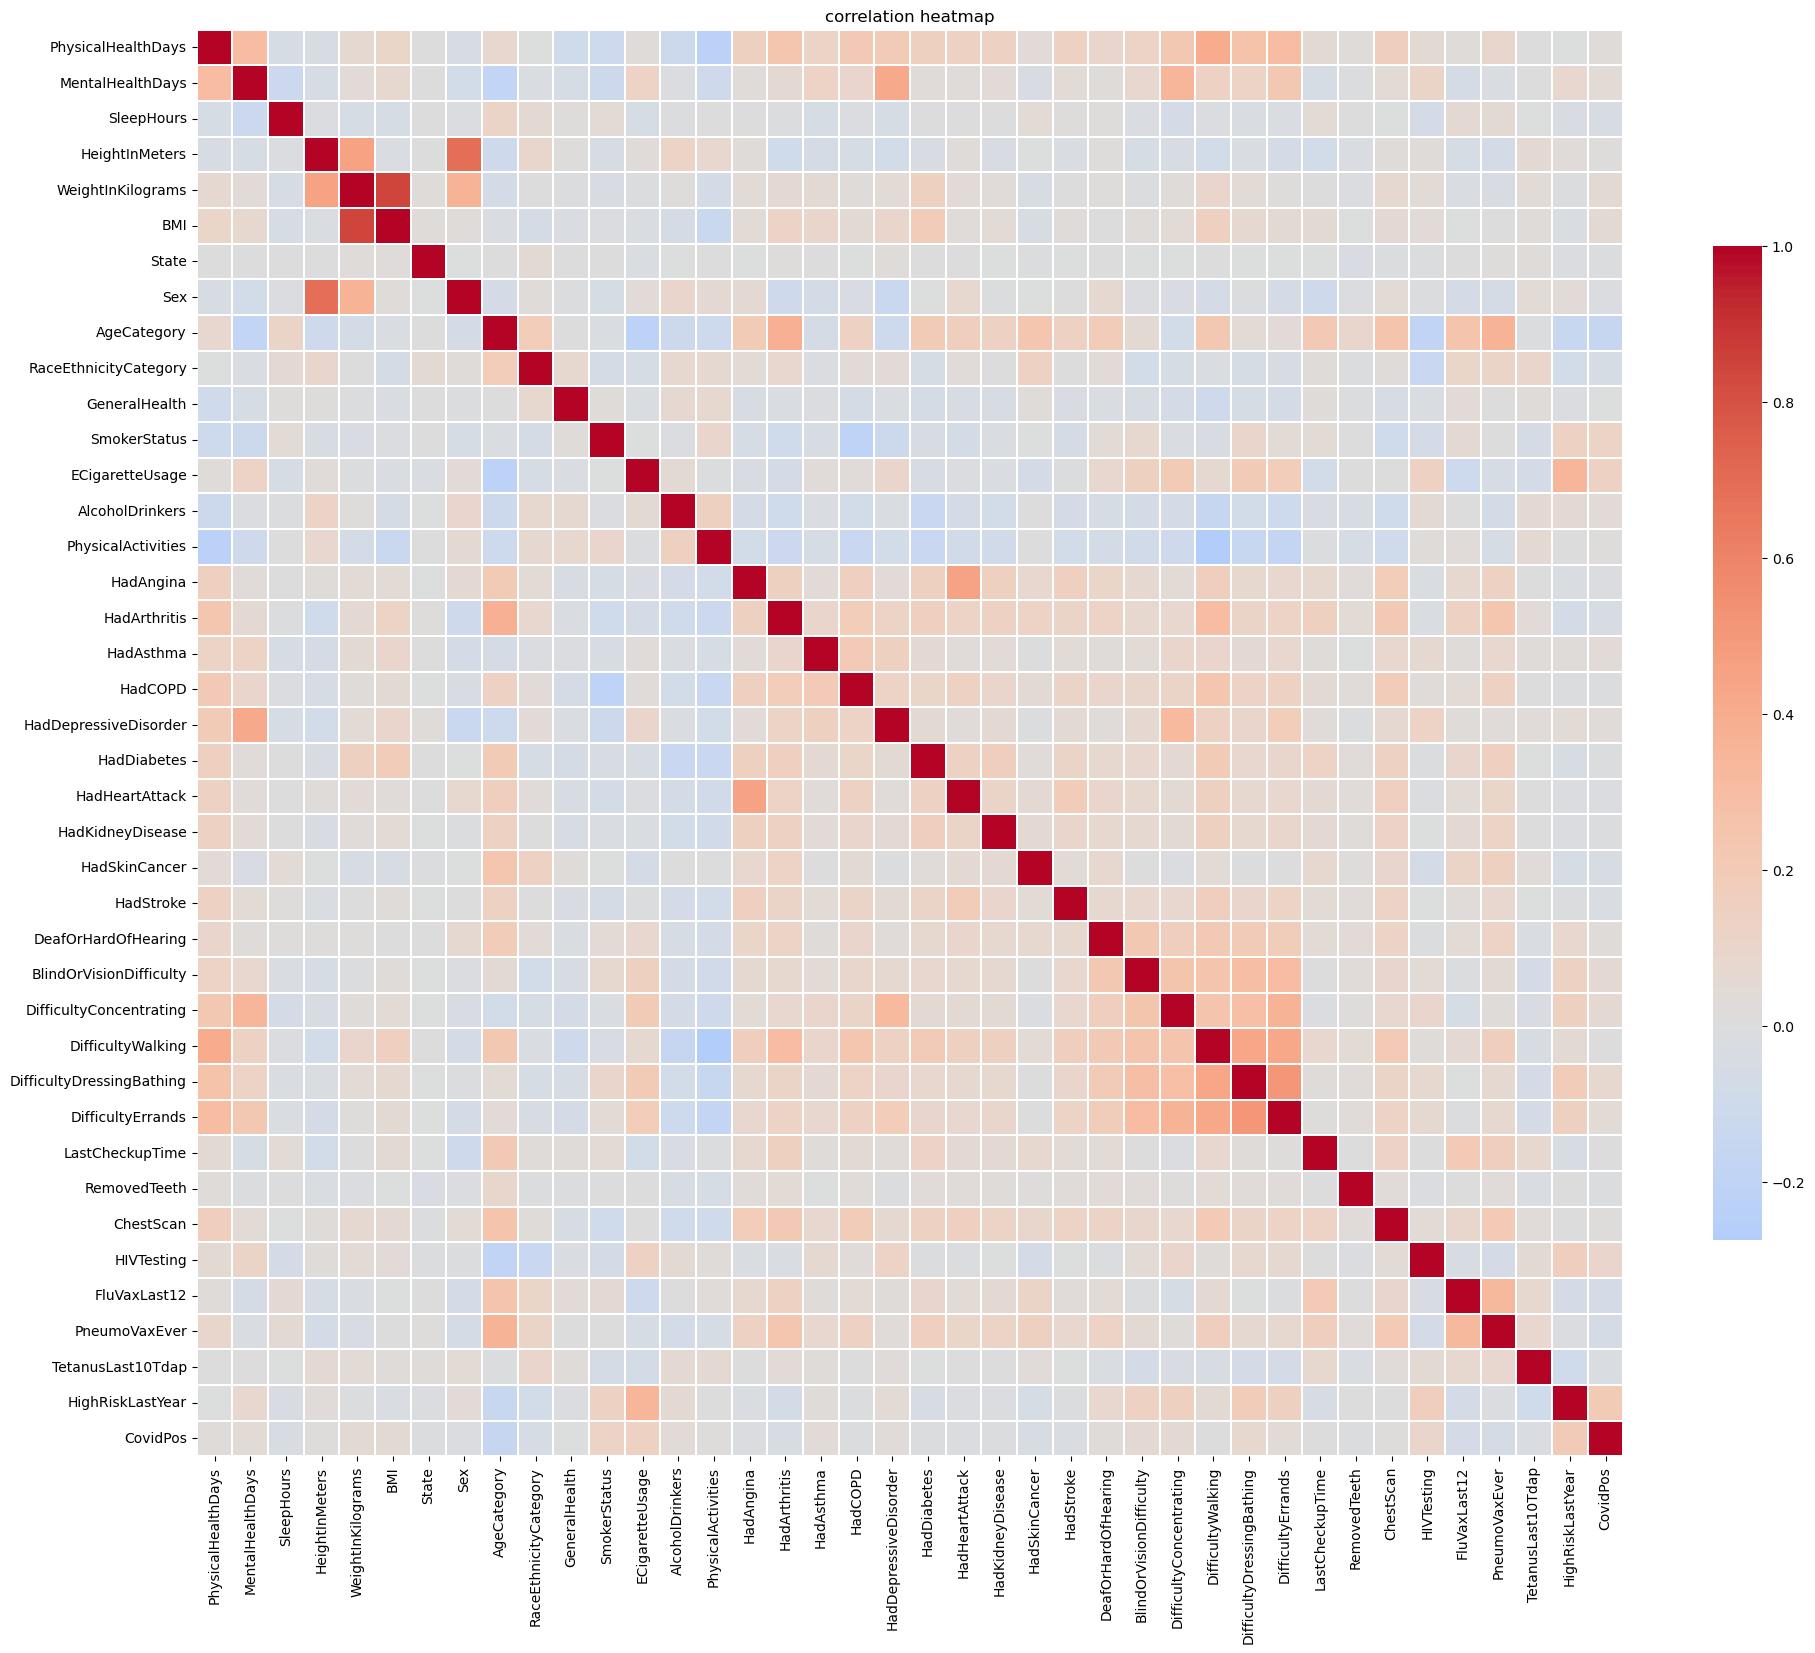

In [6]:
enc=fe.copy()
for c in enc.select_dtypes(include="object").columns:
    enc[c]=enc[c].astype("category").cat.codes
corr=enc.corr()
plt.figure(figsize=(20,18))
sns.heatmap(corr,cmap="coolwarm",center=0,square=True,linewidths=0.3,cbar_kws={"shrink":0.6})
plt.title("correlation heatmap")
plt.tight_layout()
plt.savefig("heatmap.png",dpi=120)
plt.show()

## Feature Selection

In [7]:
ct=corr["HadHeartAttack"].drop("HadHeartAttack").sort_values(key=abs,ascending=False)
print(ct.round(3))
sel=ct[ct.abs()>=0.02].index.tolist()
dropped=[c for c in fe.columns if c not in sel and c!="HadHeartAttack"]
print("selected",len(sel))
print("dropped",dropped)

HadAngina                    0.447
HadStroke                    0.189
AgeCategory                  0.171
ChestScan                    0.162
DifficultyWalking            0.158
HadDiabetes                  0.144
HadCOPD                      0.144
PhysicalHealthDays           0.138
HadArthritis                 0.124
HadKidneyDisease             0.117
PneumoVaxEver                0.109
DeafOrHardOfHearing          0.097
PhysicalActivities          -0.086
DifficultyErrands            0.085
DifficultyDressingBathing    0.074
SmokerStatus                -0.073
AlcoholDrinkers             -0.071
Sex                          0.071
BlindOrVisionDifficulty      0.070
LastCheckupTime              0.060
HadSkinCancer                0.055
DifficultyConcentrating      0.050
FluVaxLast12                 0.045
GeneralHealth               -0.038
WeightInKilograms            0.038
HadDepressiveDisorder        0.030
BMI                          0.030
HadAsthma                    0.028
MentalHealthDays    

## Preprocessing, SMOTE and Model

In [8]:
y=(fe["HadHeartAttack"]=="Yes").astype(int)
X=fe[sel]
numf=[c for c in num if c in X.columns]
catf=[c for c in X.columns if c not in numf]
pre=ColumnTransformer([
("num",StandardScaler(),numf),
("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),catf)])
model=Pipeline([
("pre",pre),
("smote",SMOTE(sampling_strategy=0.5,random_state=42)),
("clf",HistGradientBoostingClassifier(max_iter=100,learning_rate=0.1,max_leaf_nodes=63,random_state=42))])

## Cross Validation

In [9]:
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
scores=cross_validate(model,X,y,cv=cv,scoring=["accuracy","roc_auc","recall","precision","f1","balanced_accuracy"],n_jobs=1)
for k in ["accuracy","roc_auc","recall","precision","f1","balanced_accuracy"]:
    print(k,round(scores["test_"+k].mean(),4))

accuracy 0.9461
roc_auc 0.8874
recall 0.3105
precision 0.5446
f1 0.3955
balanced_accuracy 0.6474


## Threshold Tuning and Evaluation

threshold 0.25
roc_auc 0.888
balanced_accuracy 0.7458
              precision    recall  f1-score   support

           0     0.9715    0.9597    0.9656     62545
           1     0.4430    0.5319    0.4834      3766

    accuracy                         0.9354     66311
   macro avg     0.7073    0.7458    0.7245     66311
weighted avg     0.9415    0.9354    0.9382     66311



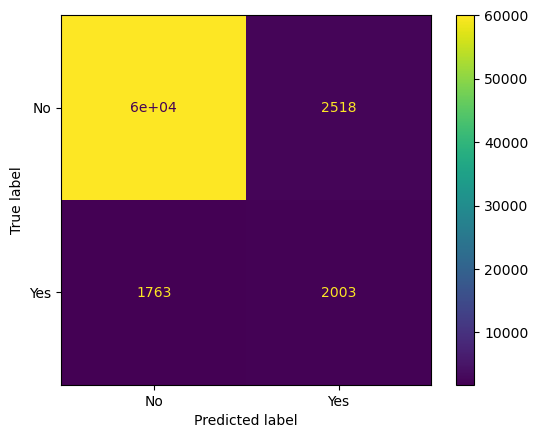

In [10]:
Xtr,Xtmp,ytr,ytmp=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
Xval,Xte,yval,yte=train_test_split(Xtmp,ytmp,test_size=0.5,random_state=42,stratify=ytmp)
model.fit(Xtr,ytr)
pv=model.predict_proba(Xval)[:,1]
pt=model.predict_proba(Xte)[:,1]
th=max(np.linspace(0.1,0.9,81),key=lambda t:f1_score(yval,(pv>=t).astype(int)))
pred=(pt>=th).astype(int)
print("threshold",round(th,3))
print("roc_auc",round(roc_auc_score(yte,pt),4))
print("balanced_accuracy",round(balanced_accuracy_score(yte,pred),4))
print(classification_report(yte,pred,digits=4))
ConfusionMatrixDisplay(confusion_matrix(yte,pred),display_labels=["No","Yes"]).plot()
plt.show()